In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans , DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import train_test_split ,GridSearchCV,cross_val_score,RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import joblib


url = "../data/raw/dataset.csv"

df = pd.read_csv(url)

# df


1. Exploratory Data Analysis (EDA)

In [2]:
df.shape , df.info() , df.head() , df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   str    
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), str(1)
memory usage: 611.9 KB


((8950, 8),
 None,
   CUST_ID      BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  \
 0  C10001    40.900749      95.40              0.00                    95.4   
 1  C10002  3202.467416       0.00              0.00                     0.0   
 2  C10003  2495.148862     773.17            773.17                     0.0   
 3  C10004  1666.670542    1499.00           1499.00                     0.0   
 4  C10005   817.714335      16.00             16.00                     0.0   
 
    CASH_ADVANCE  CREDIT_LIMIT     PAYMENTS  
 0      0.000000        1000.0   201.802084  
 1   6442.945483        7000.0  4103.032597  
 2      0.000000        7500.0   622.066742  
 3    205.788017        7500.0     0.000000  
 4      0.000000        1200.0   678.334763  ,
             BALANCE     PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  \
 count   8950.000000   8950.000000       8950.000000             8950.000000   
 mean    1564.474828   1003.204834        592.437371          

In [3]:
df.select_dtypes(include="number").skew()
# strongly right-skewed

BALANCE                    2.393386
PURCHASES                  8.144269
ONEOFF_PURCHASES          10.045083
INSTALLMENTS_PURCHASES     7.299120
CASH_ADVANCE               5.166609
CREDIT_LIMIT               1.522464
PAYMENTS                   5.907620
dtype: float64

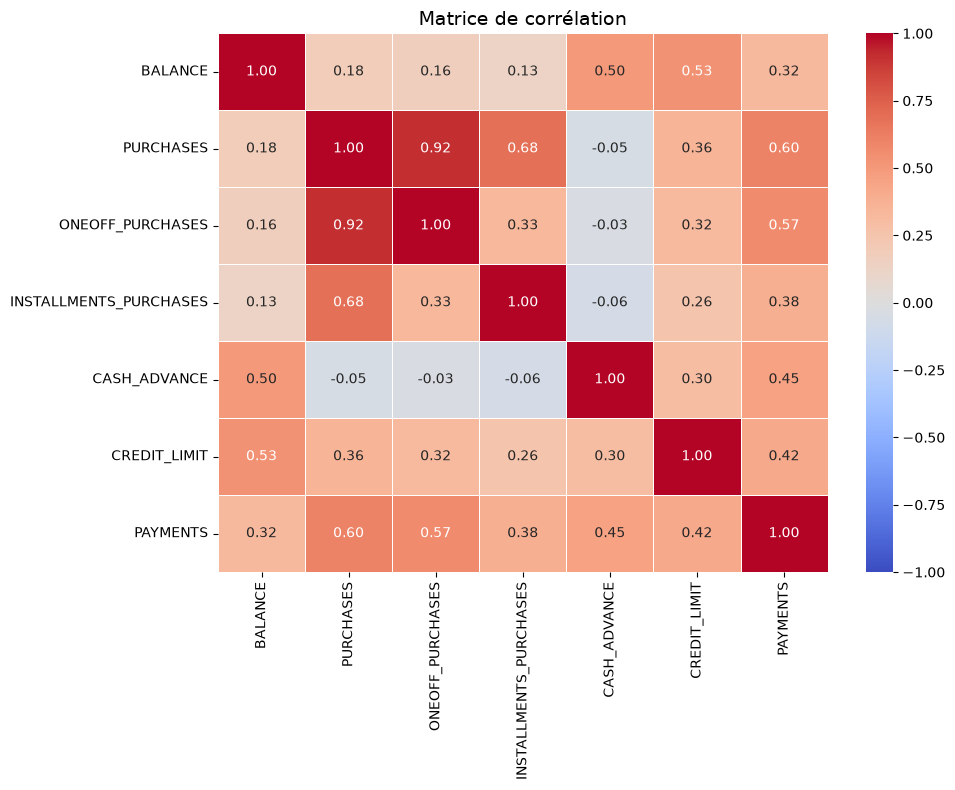

In [4]:
corr_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10 , 8))

sns.heatmap(
    corr_matrix,
    annot = True,
    fmt=".2f",
    cmap = "coolwarm",
    vmin= -1 , vmax= 1,
    linewidths=0.5
)

plt.title("Matrice de corrélation" , fontsize = 14)
plt.tight_layout()
plt.show()

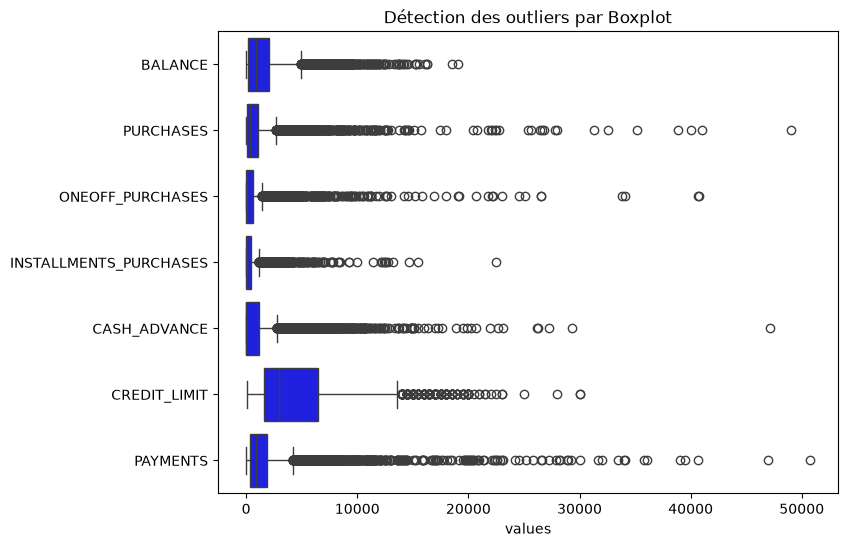

In [5]:
plt.figure(figsize=(8 , 6))

sns.boxplot(
    data = df.select_dtypes(include="number"),
    orient="h",
    color = "blue"
)

plt.title("Détection des outliers par Boxplot")
plt.xlabel("values")

plt.show()

In [6]:

number_type = df.select_dtypes(include="number")
Q1 = number_type.quantile(0.25)
Q3 = number_type.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_Outliers = ((number_type < lower) | (number_type > upper)).sum()

df_Outliers

BALANCE                    695
PURCHASES                  808
ONEOFF_PURCHASES          1013
INSTALLMENTS_PURCHASES     867
CASH_ADVANCE              1030
CREDIT_LIMIT               248
PAYMENTS                   808
dtype: int64

In [7]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_count.sort_values(ascending=False) , missing_percent

(CREDIT_LIMIT              1
 CUST_ID                   0
 PURCHASES                 0
 BALANCE                   0
 ONEOFF_PURCHASES          0
 INSTALLMENTS_PURCHASES    0
 CASH_ADVANCE              0
 PAYMENTS                  0
 dtype: int64,
 CUST_ID                   0.000000
 BALANCE                   0.000000
 PURCHASES                 0.000000
 ONEOFF_PURCHASES          0.000000
 INSTALLMENTS_PURCHASES    0.000000
 CASH_ADVANCE              0.000000
 CREDIT_LIMIT              0.011173
 PAYMENTS                  0.000000
 dtype: float64)

Feature Story 2 : Prétraitement des données


In [8]:
df_clean = df.copy()

df_clean = df_clean.drop(columns = ["CUST_ID"])

df_clean = df_clean.dropna()

# df_clean.isna().sum()

In [9]:
df_prepare_clustering = df_clean.copy()

num_colu = df_prepare_clustering.select_dtypes(include="number").columns

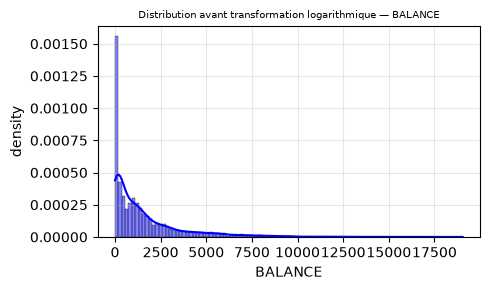

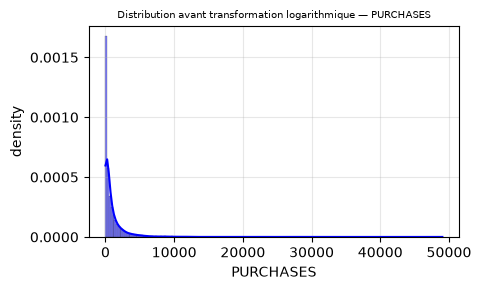

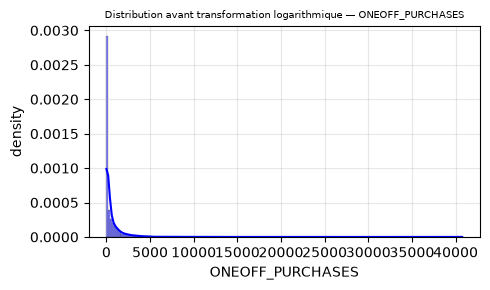

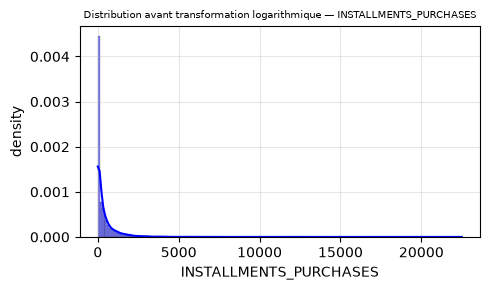

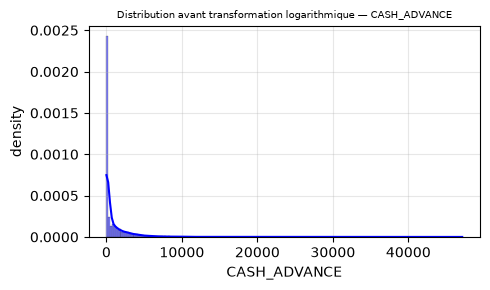

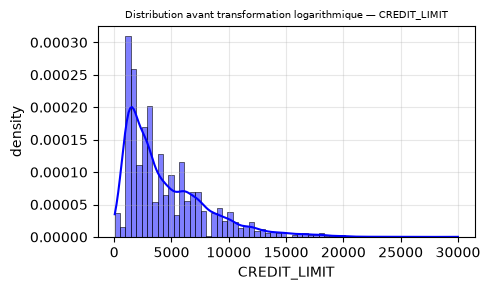

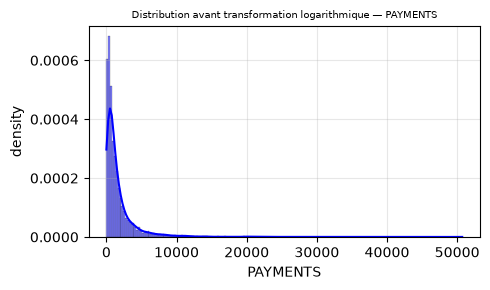

In [10]:
for col in num_colu:
  plt.figure(figsize=(5 , 3))
  sns.histplot(
      df_prepare_clustering[col] ,
      kde=True,
      color = "blue",
      stat="density"
  )

  plt.title(f"Distribution avant transformation logarithmique — {col}", fontsize=7)

  plt.xlabel(col)
  plt.ylabel("density")
  plt.grid(True , alpha=0.3)
  plt.tight_layout()
  plt.show()

In [11]:

skew_before = df_prepare_clustering[num_colu].skew()

df_prepare_clustering[num_colu] = np.log1p(df_prepare_clustering[num_colu])

skew_after = df_prepare_clustering[num_colu].skew()

skew_table = pd.DataFrame({
    "Skewness Before": skew_before,
    "Skewness After": skew_after
})

skew_table

,Skewness Before,Skewness After
BALANCE,2.393270,-0.861421
PURCHASES,8.143969,-0.764844
ONEOFF_PURCHASES,10.044622,0.185650
INSTALLMENTS_PURCHASES,7.298823,-0.025206
CASH_ADVANCE,5.166323,0.262755
CREDIT_LIMIT,1.522464,-0.101438
PAYMENTS,5.907465,-1.779084


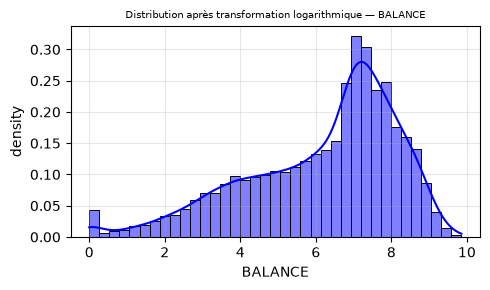

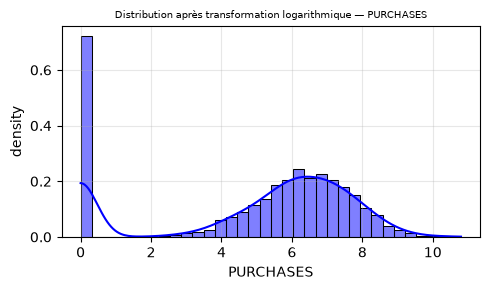

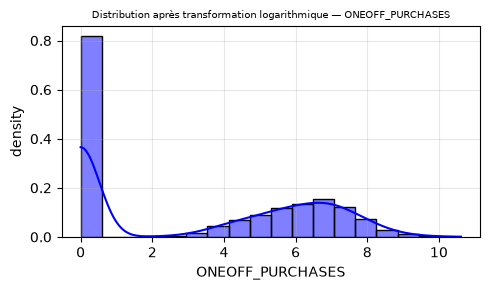

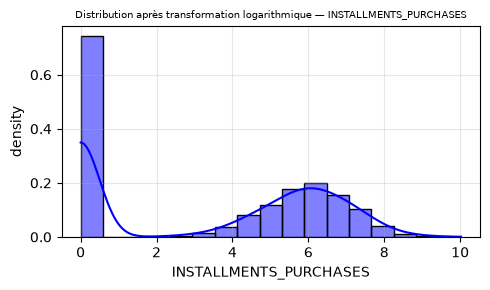

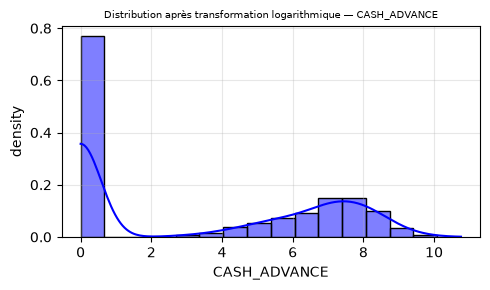

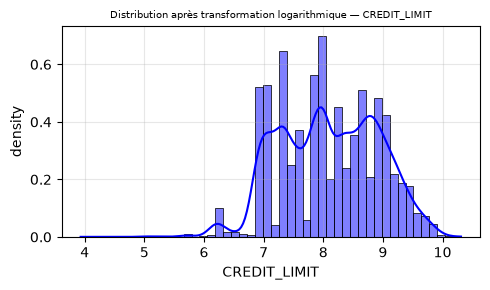

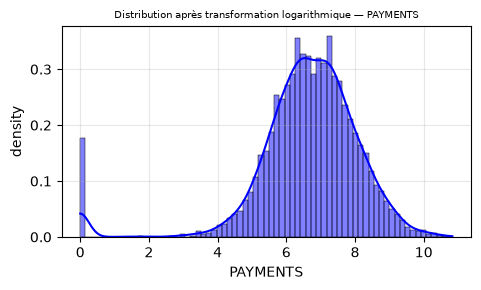

In [12]:
for col in num_colu:
  plt.figure(figsize=(5 , 3))
  sns.histplot(
      df_prepare_clustering[col] ,
      kde=True,
      color = "blue",
      stat="density"
  )

  plt.title(f"Distribution après transformation logarithmique — {col}", fontsize=7)

  plt.xlabel(col)
  plt.ylabel("density")
  plt.grid(True , alpha=0.3)
  plt.tight_layout()
  plt.show()

In [13]:
scaler = StandardScaler()

df_scaled = scaler.fit_transform(df_prepare_clustering[num_colu])

df_scaled.mean().round(4) , df_scaled.std().round(4)

(np.float64(0.0), np.float64(1.0))

PCA — Réduction dimensionnelle

In [14]:
pca = PCA()

x_pca = pca.fit(df_scaled)

exp_var_rat = x_pca.explained_variance_ratio_

cum_exp = np.cumsum(exp_var_rat)

pca_argmax = np.argmax(cum_exp >= 0.80) + 1

exp_var_rat , cum_exp , pca_argmax

(array([0.35362368, 0.29258546, 0.11396981, 0.10005366, 0.07626569,
        0.04970048, 0.01380122]),
 array([0.35362368, 0.64620914, 0.76017895, 0.86023261, 0.9364983 ,
        0.98619878, 1.        ]),
 np.int64(4))

In [15]:
# pca_cols = [f"PC{i + 1}" for i in range(4)]

# df_pca = pd.DataFrame(x_pca , columns=pca_cols)

K-means

In [16]:
result_kmeans = []

for companent in range(2 , 6):
  X_pca = PCA(n_components=companent).fit_transform(df_scaled)

  for k in range(2 , 8):
    kmeans = KMeans(
        n_clusters= k,
        random_state = 42,
        n_init=10
    )

    lables = kmeans.fit_predict(X_pca)

    inertia = kmeans.inertia_

    silhouette  = silhouette_score(X_pca , lables)

    result_kmeans.append({
        "pca components" : companent,
        "k" : k,
        "inertia" : inertia,
        "silhouette" : silhouette
    })


result_kmeans = pd.DataFrame(result_kmeans)

# result_kmeans.sort_values(by="silhouette" , ascending=False).head(10)

In [17]:
result_kmeans.sort_values(by="silhouette" , ascending=False)

,pca components,k,inertia,silhouette
1,2,3,13244.219895,0.448740
0,2,2,23542.395938,0.430953
2,2,4,10414.983259,0.421660
3,2,5,8242.980510,0.410122
10,3,6,11704.690227,0.398559
5,2,7,5634.987347,0.397941
4,2,6,6689.621477,0.394669
9,3,5,13781.047480,0.390872
8,3,4,16448.250736,0.388787
7,3,3,20205.727848,0.382649


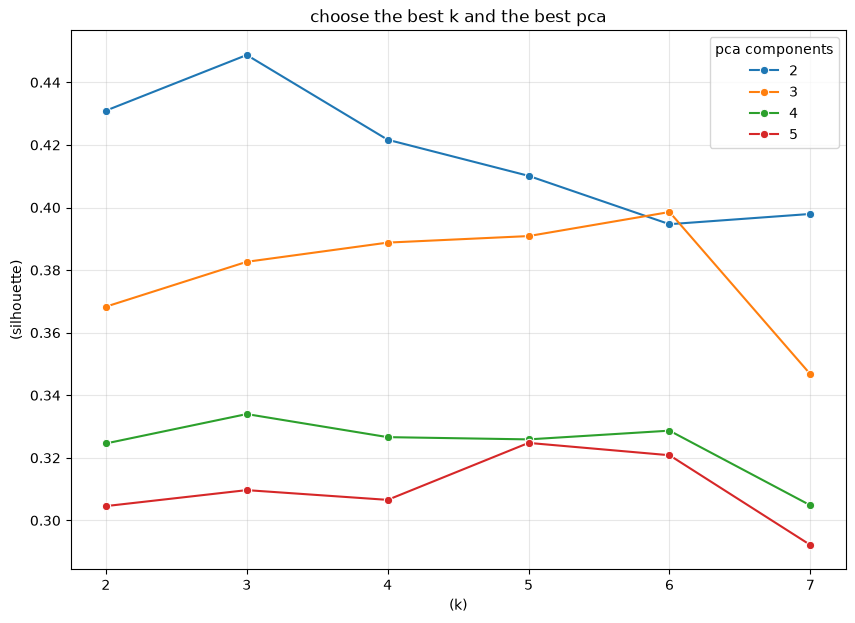

In [18]:
plt.figure(figsize=(10 , 7))

sns.lineplot(
    data=result_kmeans,
    x = "k",
    y = "silhouette",
    hue = "pca components",
    marker = "o",
    palette = "tab10"
)

plt.title("choose the best k and the best pca")
plt.xlabel("(k)")
plt.ylabel("(silhouette)")
plt.grid(True , alpha=0.3)
plt.show()

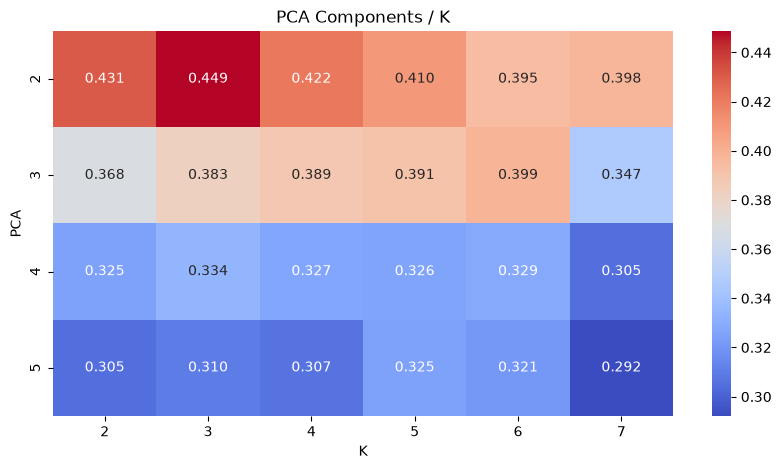

In [19]:
silhouette_pivo = result_kmeans.pivot(
    index = "pca components",
    columns = "k",
    values = "silhouette"
)

# silhouette_pivo

plt.figure(figsize=(10 , 5))

sns.heatmap(
    silhouette_pivo,
    annot = True,
    fmt = ".3f",
    cmap="coolwarm"
)

plt.title("PCA Components / K")
plt.xlabel("K")
plt.ylabel("PCA")

plt.show()

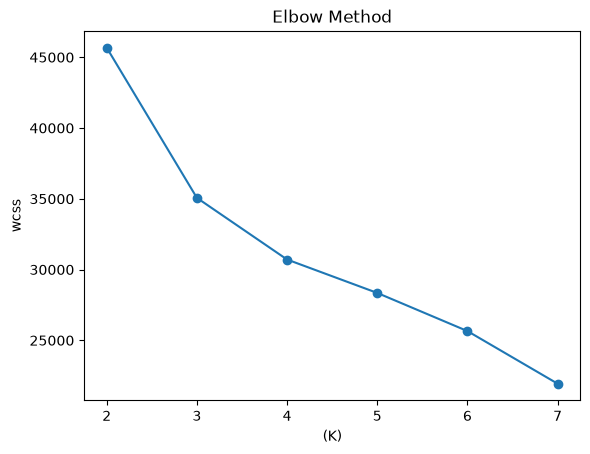

In [20]:
k_range = range(2 , 8)
wcss = []

for k in k_range:
  kmeans = KMeans(
      n_clusters = k,
      random_state = 42
  )

  kmeans.fit(df_scaled)

  wcss.append(kmeans.inertia_)

plt.plot(k_range , wcss , marker='o')
plt.title("Elbow Method")
plt.xlabel("(K)")
plt.ylabel("wcss")
plt.show()


In [21]:
pca_2 = PCA(n_components=2)
x_pca_2 = pca_2.fit_transform(df_scaled)

kmeans = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)

clusters = kmeans.fit_predict(x_pca_2)

cluster_balance = pd.DataFrame({
    "cluster" : clusters
}).value_counts().reset_index(name="count")

cluster_balance["percentage"] = (
    cluster_balance["count"] / len(clusters) * 100
)

cluster_balance

,cluster,count,percentage
0,1,3393,37.914851
1,2,3128,34.953626
2,0,2428,27.131523


In [22]:
pca_final = PCA(n_components=2)

x_pca_final = pca_final.fit_transform(df_scaled)

kmeans_final = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)

cluster_final = kmeans_final.fit_predict(x_pca_final)

sil_kmeans = silhouette_score(x_pca_final , cluster_final)
db_kmeans = davies_bouldin_score(x_pca_final , cluster_final)
ch_kmeans = calinski_harabasz_score(x_pca_final , cluster_final)

df_clean["cluster_kmeans"] = cluster_final
df_clean["cluster_kmeans"].value_counts()

cluster_kmeans
1    3393
2    3128
0    2428
Name: count, dtype: int64

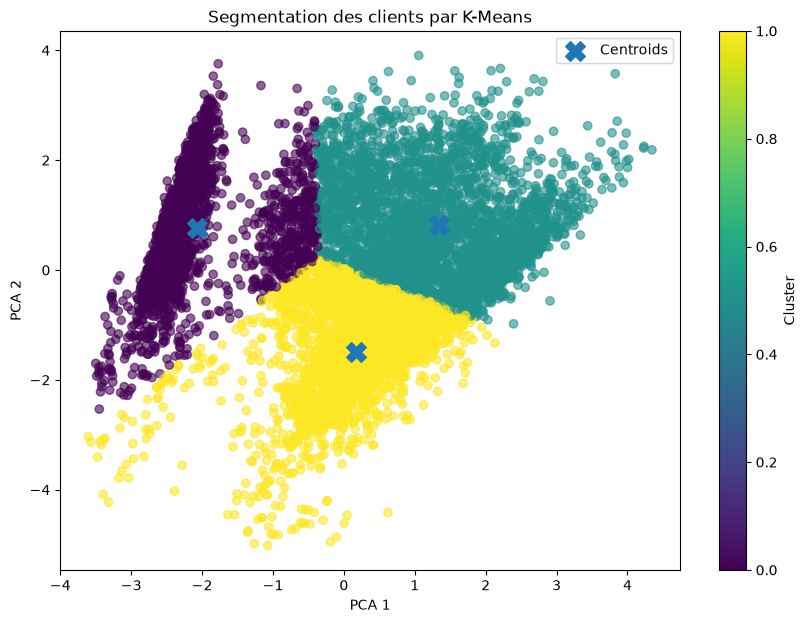

In [23]:
plt.figure(figsize=(10, 7))

plt.scatter(
    x_pca_final[:, 0],
    x_pca_final[:, 1],
    c=df_clean["cluster_kmeans"],
    alpha=0.6
)

plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("Segmentation des clients par K-Means")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster")
plt.legend()
plt.show()

DBSCAN

In [24]:
result_dbscan = []

for component in range(2 , 6):
  pca_db = PCA(n_components=component).fit_transform(df_scaled)
  for eps in [0.3 , 0.5 , 0.7 , 1.0 , 1.5]:
    for min_simples in [5 , 10 , 15]:
      dbscan = DBSCAN(
          eps = eps,
          min_samples = min_simples
      )
      lables = dbscan.fit_predict(pca_db)
      n_cluster = len(set(lables)) - (1 if -1 in lables else 0)
      noise_percentage = (lables == -1).mean() * 100

      if n_cluster >= 2 :
        mask = lables != -1
        silhoutte = silhouette_score(
            pca_db[mask],
            lables[mask]
        )
      else :
        silhoutte = np.nan


      result_dbscan.append({
            "PCA Components": component,
            "eps": eps,
            "min_samples": min_simples,
            "n_clusters": n_cluster,
            "noise_percentage": noise_percentage,
            "silhouette": silhoutte
      })
result_dbscan = pd.DataFrame(result_dbscan)
result_dbscan.sort_values(
    "silhouette",
    ascending=False
).head(10)



,PCA Components,eps,min_samples,n_clusters,noise_percentage,silhouette
2,2,0.3,15,2,1.866130,0.452707
0,2,0.3,5,2,0.301710,0.421375
47,5,0.3,15,9,69.728461,0.411167
17,3,0.3,15,5,11.420270,0.407209
1,2,0.3,10,3,1.028048,0.388007
59,5,1.5,15,2,0.178791,0.381534
35,4,0.5,15,4,9.811152,0.330418
52,5,0.7,10,4,4.805006,0.327820
56,5,1.0,15,4,1.553246,0.327430
53,5,0.7,15,4,6.537043,0.327113


In [25]:
pca_db = PCA(n_components=2).fit_transform(df_scaled)
dbscan = DBSCAN(
    eps = 0.3,
    min_samples = 15
    )

lables = dbscan.fit_predict(pca_db)

sil_dbscan = silhouette_score(pca_db , lables)
db_dbscan = davies_bouldin_score(pca_db , lables)
ch_dbscan = calinski_harabasz_score(pca_db , lables)

In [26]:
comparison = pd.DataFrame({
    "Method" : ["K-means" , "DBSCAN"],
    "nombre de cluster" : [3,2],
    "silhouette" : [0.448740,0.452707],
    "Nois precentage" : [0 , 1.86]
})

comparison

,Method,nombre de cluster,silhouette,Nois precentage
0,K-means,3,0.448740,0.00
1,DBSCAN,2,0.452707,1.86


In [27]:

tableau_comparatif = pd.DataFrame({
    "Metrique" : [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index",
        "Noise"
    ],
    "K-means" : [
        round(sil_kmeans , 3),
        round(db_kmeans , 3),
        round(ch_kmeans , 3),
        "0%"
    ],
    "DBSCAN": [
        round(sil_dbscan , 3),
        round(db_dbscan , 3),
        round(ch_dbscan , 3),
        "1.86%"
    ]
})


tableau_comparatif

,Metrique,K-means,DBSCAN
0,Silhouette Score,0.449,0.428
1,Davies-Bouldin Index,0.774,3.264
2,Calinski-Harabasz Index,9198.595,2942.211
3,Noise,0%,1.86%


In [28]:
df_clean["cluster_final"] = df_clean["cluster_kmeans"]
# df_clean["cluster_final"]

# Feature Story 4 : Analyse et interprétation des clusters


In [29]:
cluster_scaled = pd.DataFrame(
    df_scaled,
    columns = num_colu,
    index = df_clean.index
)

cluster_scaled["cluster_final"] = df_clean["cluster_final"]

cluster_names = cluster_scaled.groupby("cluster_final")[num_colu].mean()
cluster_scaled

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_final
0,-1.205498,-0.113732,-0.987198,0.394362,-0.930636,-1.447095,-0.825080,2
1,0.948821,-1.680213,-0.987198,-1.087586,1.528788,0.925997,1.065109,0
2,0.824885,0.600600,1.061910,-1.087586,-0.930636,1.010161,-0.119646,1
3,0.624529,0.827395,1.265665,-1.087586,0.564410,1.010161,-4.163779,2
4,0.271106,-0.708741,-0.114417,-1.087586,-0.930636,-1.224854,-0.065306,2
...,...,...,...,...,...,...,...,...
8945,-1.379929,0.266413,-0.987198,0.753993,-0.930636,-1.447095,-0.525611,2
8946,-1.568362,0.276681,-0.987198,0.763707,-0.930636,-1.447095,-0.629439,2
8947,-1.474137,0.027189,-0.987198,0.527678,-0.930636,-1.447095,-1.392116,2
8948,-1.734100,-1.680213,-0.987198,-1.087586,0.086095,-2.291561,-1.661991,2


In [30]:
cluster_real = df_clean.groupby("cluster_final")[num_colu].mean()
cluster_real

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
cluster_final,,,,,,,
0,2176.510572,23.804876,19.040836,4.814152,2008.694406,3982.504618,1630.551945
1,2263.951257,2198.832193,1411.376935,787.687250,1095.701917,6525.855073,2888.626501
2,331.162731,466.831007,149.386630,318.012730,53.031643,2688.325018,559.954794


In [31]:
cluster_count = df_clean["cluster_final"].value_counts().sort_index()
cluster_count

cluster_final
0    2428
1    3393
2    3128
Name: count, dtype: int64

In [32]:
cluster_percent = (cluster_count / len(df_clean) * 100).round(2)
cluster_percent

cluster_final
0    27.13
1    37.91
2    34.95
Name: count, dtype: float64

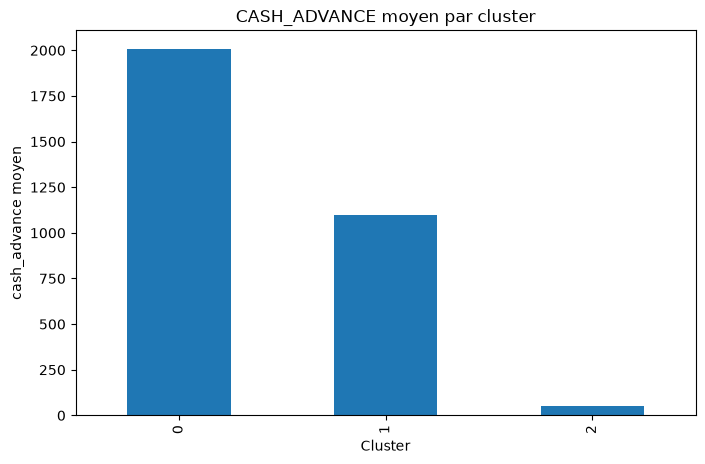

In [33]:
cluster_real["CASH_ADVANCE"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("CASH_ADVANCE moyen par cluster")
plt.xlabel("Cluster")
plt.ylabel("cash_advance moyen")
plt.show()

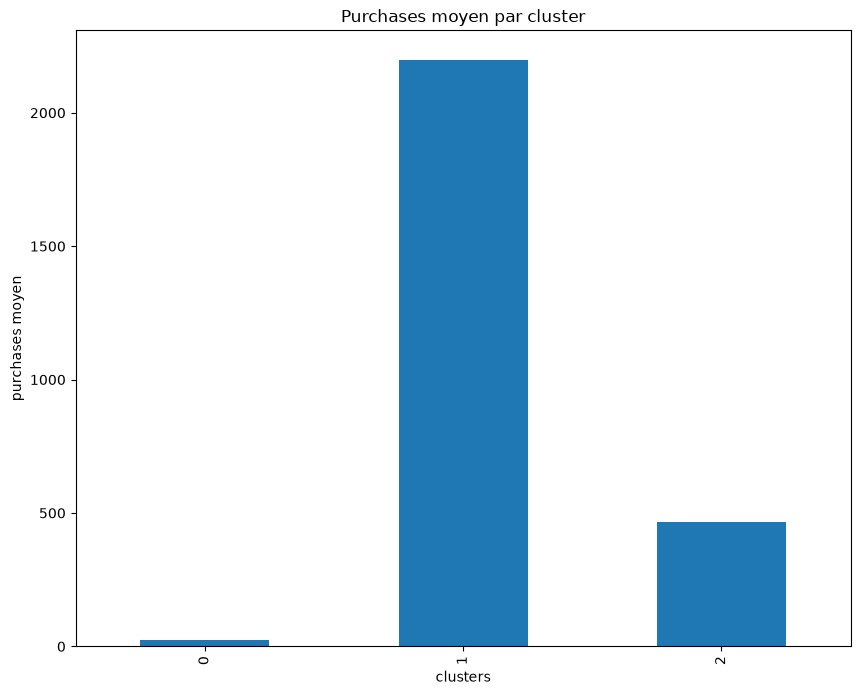

In [34]:
cluster_real["PURCHASES"].plot(
    kind="bar",
    figsize = (10 , 8)
)

plt.title("Purchases moyen par cluster")
plt.xlabel("clusters")
plt.ylabel("purchases moyen")
plt.show()

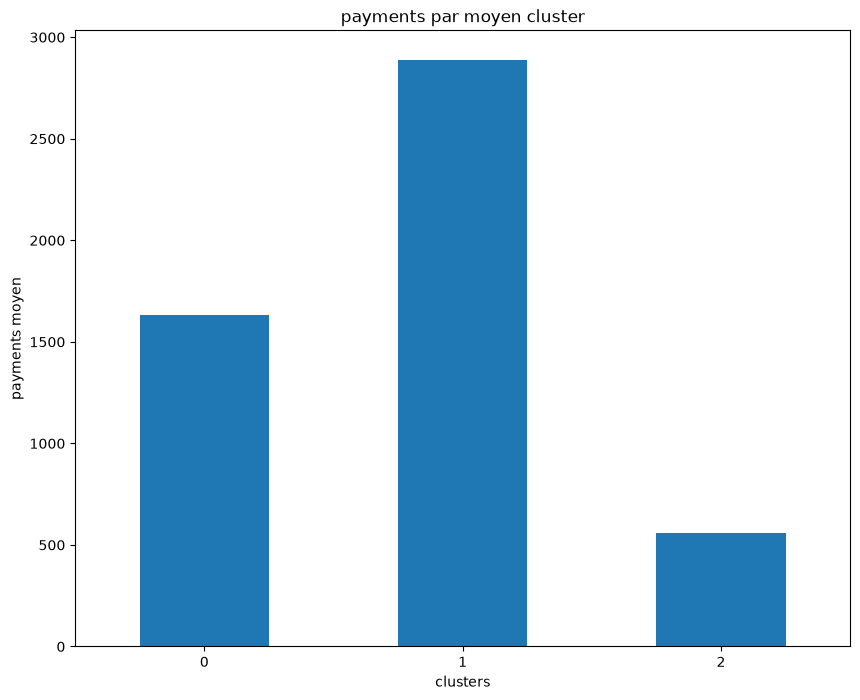

In [35]:
cluster_real["PAYMENTS"].plot(
    kind = "bar",
    figsize = (10 , 8)
)

plt.title("payments par moyen cluster")
plt.xlabel("clusters")
plt.ylabel("payments moyen")
plt.xticks(rotation=0)
plt.show()

In [36]:
cluster_names = {
    0: "Clients à Risque",
    1: "Clients Premium",
    2: "Clients à Faible Activité"
}

df_clean["target"] = df_clean["cluster_final"].map(cluster_names)
df_clean[["cluster_final", "target"]].head()

,cluster_final,target
0,2,Clients à Faible Activité
1,0,Clients à Risque
2,1,Clients Premium
3,2,Clients à Faible Activité
4,2,Clients à Faible Activité


# Feature Story 5 : Classification supervisée et évaluation des modèles

In [37]:
x = df_clean[num_colu].copy()
y = df_clean["target"].copy()

In [38]:
X_train , X_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

In [39]:
logistic_model = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Clients Premium','Clients à Faible Activité','Clients à Risque']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['BALANCE','PURCHASES','ONEOFF_PURCHASES',...,'CASH_ADVANCE', 'CREDIT_LIMIT','PAYMENTS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [40]:
y_pred_logistic = logistic_model.predict(X_test)

In [41]:
accuracy_logistic = accuracy_score(y_test , y_pred_logistic)
precision_logistic = precision_score(y_test , y_pred_logistic , average="weighted")
recall_logistic = recall_score(y_test , y_pred_logistic, average="weighted")
f1_logistic = f1_score(y_test , y_pred_logistic , average="weighted")
accuracy_logistic, precision_logistic, f1_logistic, f1_logistic

(0.9106145251396648, 0.9111758686631679, 0.91062660884478, 0.91062660884478)

In [42]:
rf_model = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , RandomForestClassifier(
        n_estimators= 200,
        random_state = 42
    ))
])

rf_model.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Clients Premium','Clients à Faible Activité','Clients à Risque']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['BALANCE','PURCHASES','ONEOFF_PURCHASES',...,'CASH_ADVANCE', 'CREDIT_LIMIT','PAYMENTS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [43]:
y_pred_rf = rf_model.predict(X_test)

In [44]:
accuracy_rf = accuracy_score(y_test , y_pred_rf)
precision_rf = precision_score(y_test , y_pred_rf, average="weighted")
recall_rf = recall_score(y_test , y_pred_rf, average="weighted")
f1_rf = f1_score(y_test , y_pred_rf, average="weighted")
accuracy_rf , precision_rf , recall_rf , f1_rf

(0.9670391061452513, 0.9672231748467871, 0.9670391061452513, 0.96707446012855)

In [45]:
tree_model = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , DecisionTreeClassifier(random_state=42))
])

tree_model.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Clients Premium','Clients à Faible Activité','Clients à Risque']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['BALANCE','PURCHASES','ONEOFF_PURCHASES',...,'CASH_ADVANCE', 'CREDIT_LIMIT','PAYMENTS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [46]:
y_pred_tree = tree_model.predict(X_test)

In [47]:
accuracy_tree = accuracy_score(y_test , y_pred_tree)
precision_tree = precision_score(y_test , y_pred_tree, average="weighted")
recall_tree = recall_score(y_test , y_pred_tree, average="weighted")
f1_tree = f1_score(y_test , y_pred_tree, average="weighted")

accuracy_tree , precision_tree , recall_tree , f1_tree

(0.9374301675977653, 0.937494714258716, 0.9374301675977653, 0.9373808423931692)

In [48]:
svc_model = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , SVC())
])

svc_model.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Clients Premium','Clients à Faible Activité','Clients à Risque']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['BALANCE','PURCHASES','ONEOFF_PURCHASES',...,'CASH_ADVANCE', 'CREDIT_LIMIT','PAYMENTS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [49]:
y_pred_svc = svc_model.predict(X_test)

In [50]:
svc_accuracy = accuracy_score(y_test , y_pred_svc)
svc_precision = precision_score(y_test , y_pred_svc , average="weighted")
svc_recall = recall_score(y_test , y_pred_svc, average="weighted")
svc_f1 = f1_score(y_test , y_pred_svc , average="weighted")

svc_accuracy,svc_precision,svc_recall,svc_f1

(0.9089385474860335,
 0.9101736728605146,
 0.9089385474860335,
 0.9088381550034451)

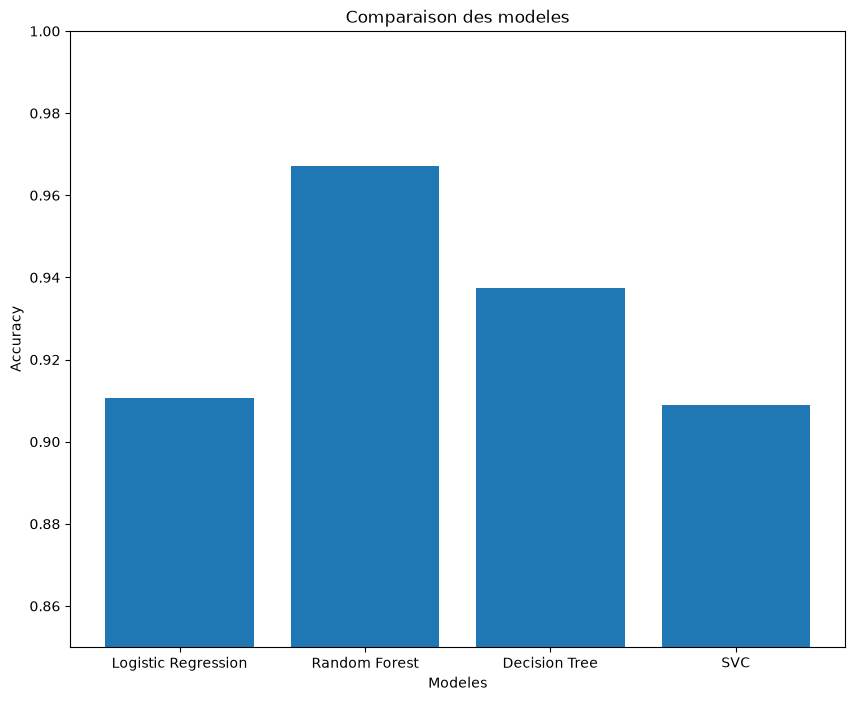

In [51]:
models = [
    "Logistic Regression",
    "Random Forest",
    "Decision Tree",
    "SVC"
]

accuracies = [
    accuracy_logistic,
    accuracy_rf,
    accuracy_tree,
    svc_accuracy
]

plt.figure(figsize = (10 , 8))

plt.bar(models , accuracies)
plt.title("Comparaison des modeles")
plt.xlabel("Modeles")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1)

plt.show()

In [52]:
cm = confusion_matrix(y_test , y_pred_rf)

# Confusion Matrix،

<Figure size 1000x1000 with 0 Axes>

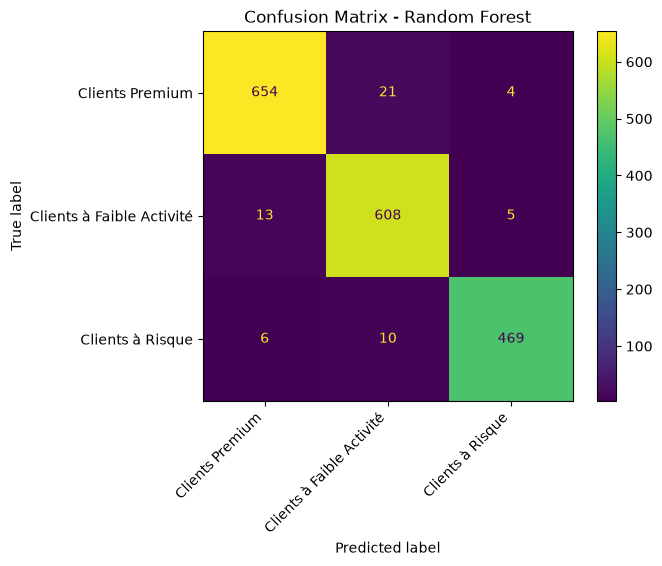

In [53]:
plt.figure(figsize=(10, 10))

cm = confusion_matrix(y_test , y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = rf_model.classes_
)

disp.plot()
plt.xticks(rotation=45, ha='right')
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [54]:
cv_score = cross_val_score(
    rf_model,
    x,
    y,
    cv = 5,
    scoring = "accuracy"
)
cv_score

array([0.96927374, 0.96648045, 0.98044693, 0.96759777, 0.96198994])

In [55]:
cv_score.mean()

np.float64(0.9691577642389401)

In [56]:
cv_score.std()

np.float64(0.006139022812932964)

In [57]:
param_grid_rf = {
    "model__n_estimators" : [100 , 200 , 300],
    "model__max_depth": [None , 10 , 20],
    "model__min_samples_split":[2 ,5]
}

grid_search_rf = GridSearchCV(
    rf_model,
    param_grid_rf,
    cv=5,
    scoring = "accuracy",
    n_jobs = -1
)

grid_search_rf.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [58]:
grid_search_rf.best_params_

{'model__max_depth': 20,
 'model__min_samples_split': 5,
 'model__n_estimators': 300}

In [59]:
param_grid_logistic = {
    "model__C" : [0.01 , 0.1 , 1 , 10 , 100]
}

grid_logistic = GridSearchCV(
    logistic_model,
    param_grid_logistic,
    cv = 5,
    scoring = "accuracy",
    n_jobs = -1,
)

grid_logistic.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, 

In [60]:
grid_logistic.best_params_

{'model__C': 100}

In [61]:
param_grid_tree = {
    "model__max_depth" : [None , 5 , 10 , 20],
    "model__min_samples_split" : [2 , 5 , 10]
}

grid_tree = GridSearchCV(
    tree_model,
    param_grid_tree,
    cv= 5 ,
    scoring = "accuracy",
    n_jobs= -1
)

grid_tree.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the ve

In [62]:
grid_tree.best_params_

{'model__max_depth': 10, 'model__min_samples_split': 2}

In [63]:
param_grid_tree = {
    "model__C" : [0.1 , 1 , 10 , 100],
    "model__kernel" : ["rbf" , "linear"],
    "model__gamma" : ["scale" , "auto"]
}

grid_svc = GridSearchCV(
    svc_model,
    param_grid_tree,
    cv = 5,
    scoring = "accuracy",
    n_jobs = -1
)

grid_svc.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['rbf', 'linear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

In [64]:
grid_svc.best_params_

{'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

In [65]:
best_logistic = grid_logistic.best_estimator_
best_rf = grid_search_rf.best_estimator_
best_tree = grid_tree.best_estimator_
best_svc = grid_svc.best_estimator_

y_pred_logistic_best = best_logistic.predict(X_test)
y_pred_rf_best = best_rf.predict(X_test)
y_pred_tree_best = best_tree.predict(X_test)
y_pred_svc_best = best_svc.predict(X_test)



In [66]:
accuracy_best_logistic = accuracy_score(y_test , y_pred_logistic_best)
accuracy_best_rf = accuracy_score(y_test , y_pred_rf_best)
accuracy_best_tree = accuracy_score(y_test , y_pred_tree_best)
accuracy_best_svc = accuracy_score(y_test , y_pred_svc_best)

display(accuracy_best_logistic , accuracy_best_rf, accuracy_best_tree, accuracy_best_svc)

0.917877094972067

0.9653631284916201

0.9329608938547486

0.9351955307262569

In [67]:
param_dist_rf = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth" : [None, 10, 20, 30, 40],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

random_search_rf = RandomizedSearchCV(
    rf_model,
    param_distributions = param_dist_rf,
    n_iter = 10,
    cv = 10,
    scoring = "accuracy",
    random_state = 42,
    n_jobs = -1,
)

random_search_rf.fit(X_train , y_train)
display(random_search_rf.best_params_ , random_search_rf.best_score_)

{'model__n_estimators': 300,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 'log2',
 'model__max_depth': 40}

np.float64(0.9685707309450328)

In [68]:
precision_best_rf = precision_score(
    y_test,
    y_pred_rf_best,
    average="weighted"
)

recall_best_rf = recall_score(
    y_test,
    y_pred_rf_best,
    average = "weighted"
)

f1_best_rf = f1_score(
    y_test,
    y_pred_rf_best,
    average = "weighted"
)

display(precision_best_rf , recall_best_rf , f1_best_rf)

0.965655361437114

0.9653631284916201

0.9654229319210706

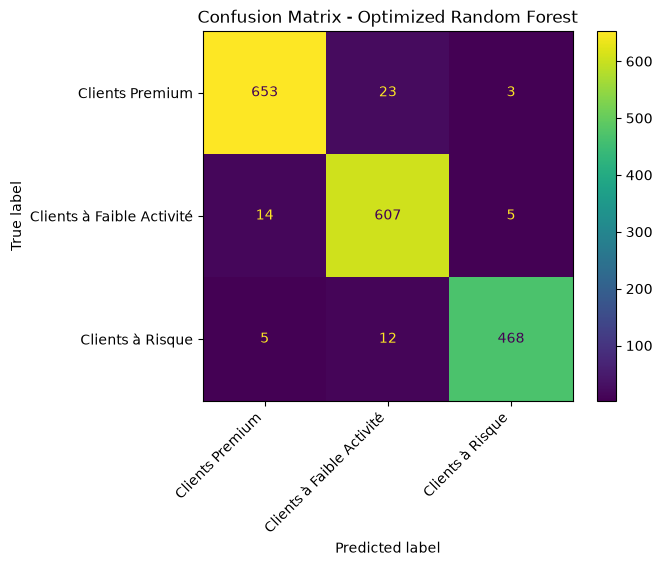

In [69]:
ConfusionMatrixDisplay.from_predictions(
    y_test , y_pred_rf_best
)

plt.title("Confusion Matrix - Optimized Random Forest")
plt.xticks(rotation=45, ha='right')
plt.show()

In [70]:
models_best = {
    "Logistic Regression" : y_pred_logistic_best,
    "Random Forest" : y_pred_rf_best,
    "Decision Tree" : y_pred_tree_best,
    "SVC" : y_pred_svc_best
}

results = []

for name , y_pred in models_best.items():
  results.append({
      "Model": name,
      "Accuracy" : accuracy_score(y_test , y_pred),
      "Precision" : precision_score(y_test , y_pred, average="weighted"),
      "Recall" : recall_score(y_test , y_pred, average="weighted"),
      "F1-score" : f1_score(y_test , y_pred , average="weighted")
  })

  results

In [71]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1-score",
    ascending = False
)

,Model,Accuracy,Precision,Recall,F1-score
1,Random Forest,0.965363,0.965655,0.965363,0.965423
3,SVC,0.935196,0.935610,0.935196,0.935149
2,Decision Tree,0.932961,0.932936,0.932961,0.932933
0,Logistic Regression,0.917877,0.918008,0.917877,0.917841


In [72]:
rf = best_rf.named_steps["model"]
feature_importent = rf.feature_importances_
feature_importent

importent_df = pd.DataFrame({
    "Features" : x.columns,
    "importents" : feature_importent
}).sort_values(
    by = "importents",
    ascending = False
)

importent_df

,Features,importents
1,PURCHASES,0.258762
2,ONEOFF_PURCHASES,0.178917
0,BALANCE,0.142929
4,CASH_ADVANCE,0.129947
6,PAYMENTS,0.112541
5,CREDIT_LIMIT,0.094965
3,INSTALLMENTS_PURCHASES,0.081940


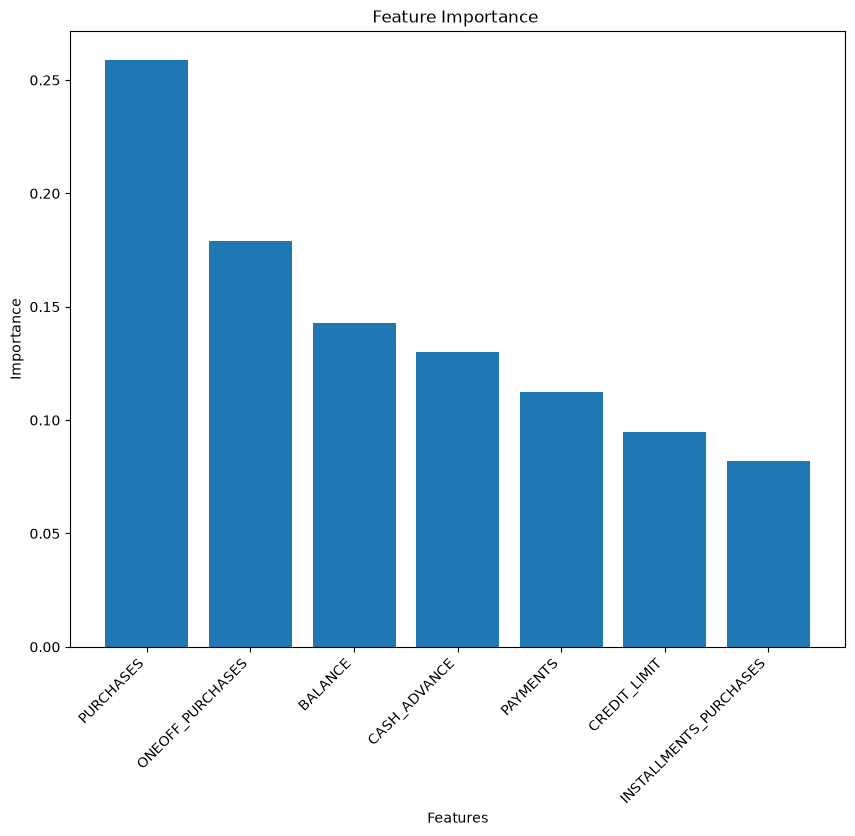

In [73]:
plt.figure(figsize = (10 , 8))

plt.bar(
    importent_df["Features"],
    importent_df["importents"]
)

plt.title("Feature Importance ")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha='right')
plt.show()

In [74]:
cv_scores_rf = cross_val_score(
    best_rf,
    x,
    y,
    cv = 5,
    scoring = "accuracy"
)

cv_scores_rf

array([0.96871508, 0.96312849, 0.97988827, 0.96871508, 0.96646171])

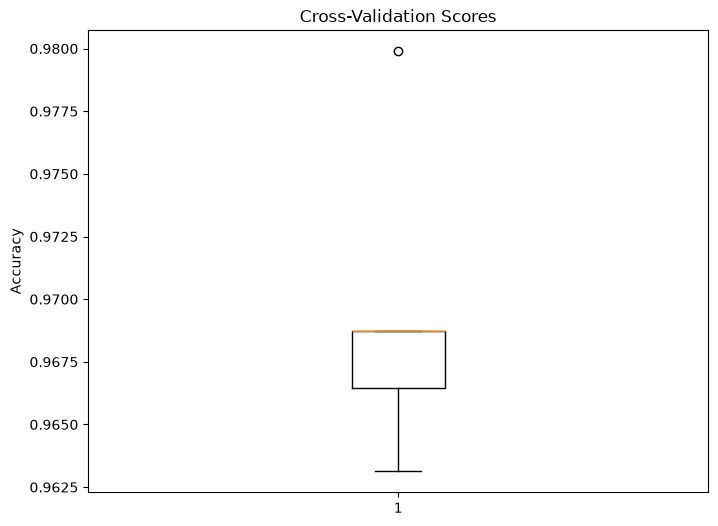

In [75]:
plt.figure(figsize=(8 , 6))
plt.boxplot(cv_scores_rf)
plt.title("Cross-Validation Scores")
plt.ylabel("Accuracy")
plt.show()

In [77]:
model_path = "../models/credit_card_customer_segmentation_pipeline.pkl"

joblib.dump(best_rf , model_path)

['../models/credit_card_customer_segmentation_pipeline.pkl']